Data comparison

Train data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy
from background.WIP_train_analysis import (
    load_train_data,
    filter_cancellation_days,
    analyse_delays,
    analyse_delays_per_hour,
    analyse_punctuality,
    analyse_delay_absorption,
    analyse_correlations
)
import importlib
import background.WIP_train_analysis 

importlib.reload(background.WIP_train_analysis )


import matplotlib.dates as mdates
from matplotlib.colors import BoundaryNorm




Weather

Filtered dataset contains 336 records for the selected period.


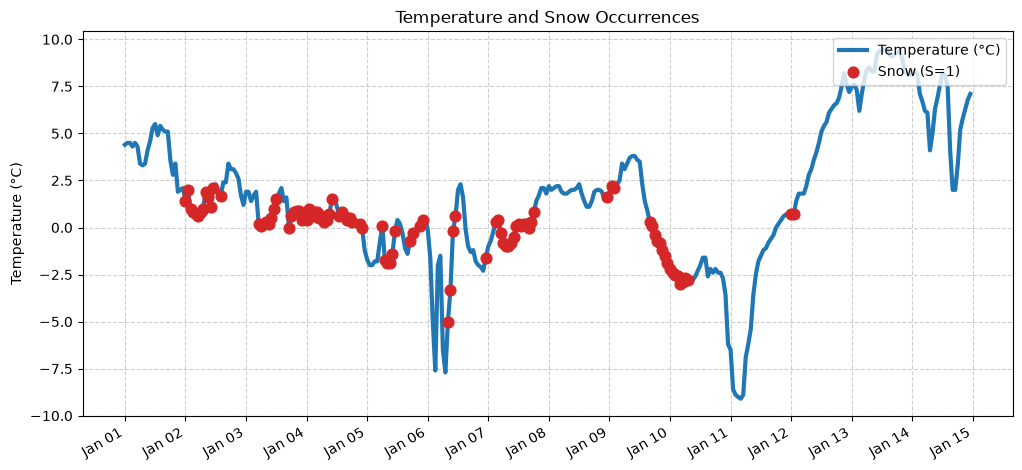

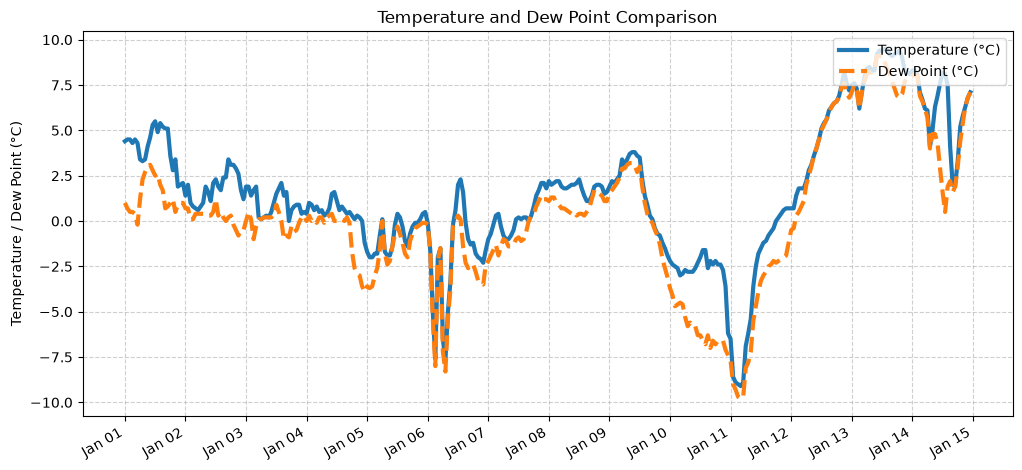

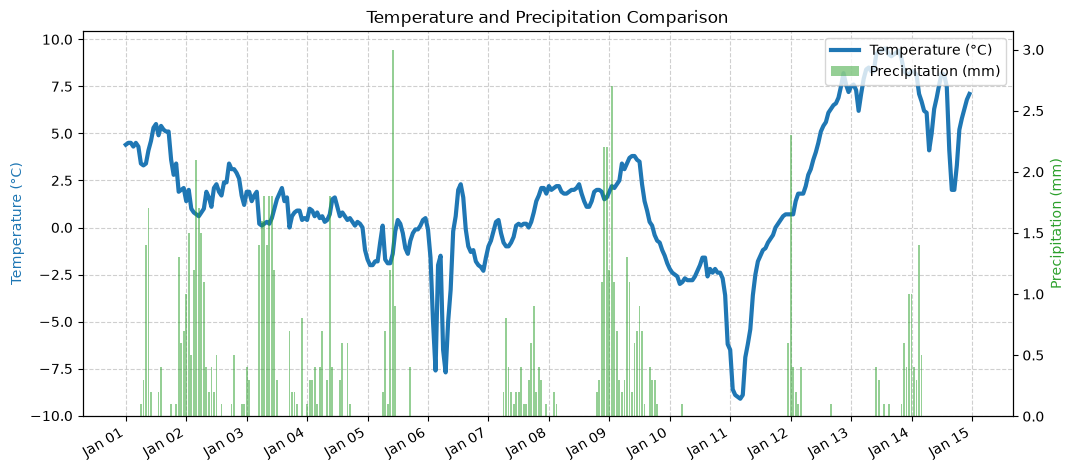

In [3]:

# 1. Load the dataset
# Make sure your file is saved in the same directory and named accordingly.
filename = 'uurgeg_260_2021-2030-2.txt'

# Find the header row starting with '# STN'
with open(filename, 'r', encoding='utf-8') as f:
    lines = f.readlines()

header_idx = next(i for i, line in enumerate(lines) if line.strip().startswith('# STN'))

# Read the data into a pandas DataFrame
df = pd.read_csv(
    filename,
    skiprows=header_idx,
    skipinitialspace=True
)

# Clean column names by removing '#' and extra whitespace
df.columns = df.columns.str.replace('#', '').str.strip()

# 2. Process Dates and Hours
# KNMI hourly data uses hours 1 to 24. We convert hour 24 properly by adjusting HH - 1.
df['HH_adjusted'] = df['HH'] - 1
df['datetime'] = pd.to_datetime(df['YYYYMMDD'].astype(str), format='%Y%m%d') + pd.to_timedelta(df['HH_adjusted'], unit='h')

# Convert KNMI scaled values to standard units:
# T: Temperature in 0.1 °C -> divide by 10
# TD: Dew point temperature in 0.1 °C -> divide by 10
df['T_C'] = df['T'] / 10.0
df['TD_C'] = df['TD'] / 10.0

# RH: Hourly precipitation amount in 0.1 mm (-1 means <0.05 mm trace amount)
# We convert -1 to 0.0 for numerical plotting, and divide valid values by 10.
df['RH_mm'] = df['RH'].apply(lambda x: 0.0 if x == -1 else x / 10.0)

# 3. Filter data for the specified period
# Note: If testing with the sample snippet from Jan 2021, change dates to '2021-01-01' and '2021-01-14'.
start_date = '2026-01-01'
end_date = '2026-01-14'

mask = (df['datetime'] >= start_date) & (df['datetime'] <= end_date + ' 23:59:59')
df_filtered = df.loc[mask].copy()

# Select columns related to weather variables
columns_of_interest = ['datetime', 'T_C', 'TD_C', 'RH_mm', 'S', 'R', 'WW', 'VV', 'U']
df_weather = df_filtered[columns_of_interest].dropna(subset=['datetime'])

print(f"Filtered dataset contains {len(df_weather)} records for the selected period.")

# 4. Visualizations - Three Completely Separate Figures

# --- Figure 1: Temperature and Snow Occurrences ---
fig1, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)

snow_df = df_weather[df_weather['S'] == 1]
ax1.scatter(snow_df['datetime'], snow_df['T_C'], color='tab:red', s=60, zorder=5, label='Snow (S=1)')

ax1.set_ylabel('Temperature (°C)')
ax1.set_title(f'Temperature and Snow Occurrences')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right')

# --- Figure 2: Temperature vs. Dew Point Comparison ---
fig2, ax2 = plt.subplots(figsize=(12, 5))
ax2.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)
ax2.plot(df_weather['datetime'], df_weather['TD_C'], label='Dew Point (°C)', color='tab:orange', linewidth=3.0, linestyle='--')

ax2.set_ylabel('Temperature / Dew Point (°C)')
ax2.set_title('Temperature and Dew Point Comparison')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right')

# --- Figure 3: Temperature and Precipitation (RH) ---
fig3, ax3_temp = plt.subplots(figsize=(12, 5))
ax3_precip = ax3_temp.twinx()  # Secondary Y-axis for precipitation

ax3_temp.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)
ax3_precip.bar(df_weather['datetime'], df_weather['RH_mm'], label='Precipitation (mm)', color='tab:green', alpha=0.5, width=0.03)

ax3_temp.set_ylabel('Temperature (°C)', color='tab:blue')
ax3_precip.set_ylabel('Precipitation (mm)', color='tab:green')
ax3_temp.set_title('Temperature and Precipitation Comparison')
ax3_temp.grid(True, linestyle='--', alpha=0.6)

# Combine legends from both axes on Figure 3
lines_1, labels_1 = ax3_temp.get_legend_handles_labels()
lines_2, labels_2 = ax3_precip.get_legend_handles_labels()
ax3_temp.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')


# --- Axis Formatting for All Independent Figures ---
for ax in [ax1, ax2, ax3_temp]:
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')



In [10]:
df_train = load_train_data(start_period= '01-01-2026', end_period= '15-01-2026')


hourly = df_train.groupby('arr_hour').agg(
        arrival_mean=('arr_delay', 'mean'),
        departure_mean=('dep_delay', 'mean'),
        arrival_median=('arr_delay', 'median'),
        departure_median=('dep_delay', 'median'),
        arrival_delayed=('arrival_delayed', 'mean'),
        departure_delayed=('departure_delayed', 'mean'),
        arrival_delayed_3=('arrival_delayed_3', 'mean'),
        departure_delayed_3=('departure_delayed_3', 'mean'),
        cancelled=('cancelled', 'mean'),
        n_trains=('train_id', 'count')
    )

Comparison

          arrival_mean  departure_mean  arrival_median  departure_median  \
arr_hour                                                                   
5.0           0.443333        0.343333             0.0               0.0   
6.0           0.644195        0.543071             0.0               0.0   
7.0           1.083591        0.941176             0.0               0.0   
8.0           1.079320        0.696884             0.0               0.0   
9.0           1.337517        0.822873             0.0               0.0   
10.0          0.764624        0.582173             0.0               0.0   
11.0          0.707977        0.622507             0.0               0.0   
12.0          1.095170        0.926136             0.0               0.0   
13.0          0.818966        0.696839             0.0               0.0   
14.0          0.941828        0.832410             0.0               0.0   
15.0          1.410468        1.272727             0.0               0.0   
16.0        

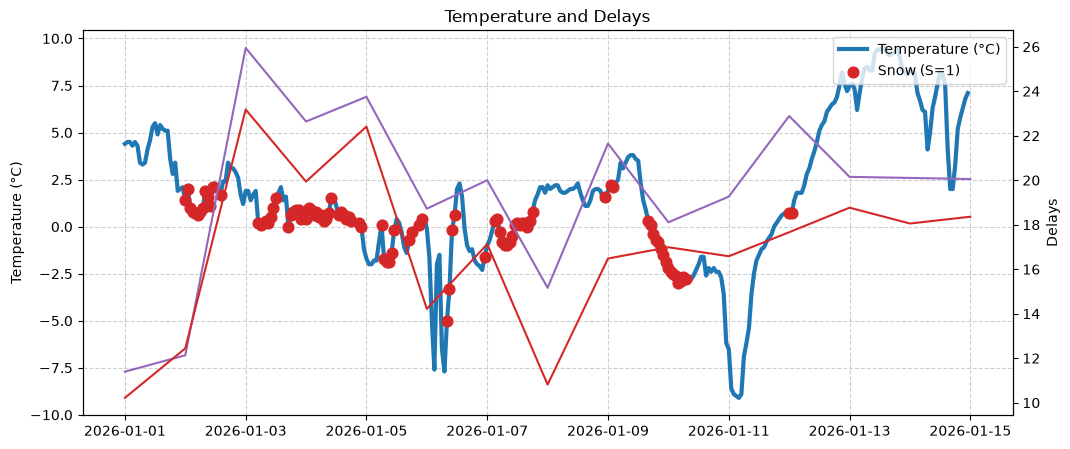

In [ ]:
#Visualisation 1

df_train = load_train_data(start_period= '01-01-2026', end_period= '15-01-2026')


daily_delay = df_train.groupby(df_train['Date'].dt.normalize()).agg(
        arrival_delayed=('arrival_delayed', 'mean'),
        departure_delayed=('departure_delayed', 'mean'),
        arrival_delayed_3=('arrival_delayed_3', 'mean'),
        departure_delayed_3=('departure_delayed_3', 'mean'),
        cancelled=('cancelled', 'mean')
    ) * 100


fig1, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

ax1.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)
ax2.plot(daily_delay.index, daily_delay['arrival_delayed'],
        label='Arrival Delays', color = 'tab:purple')
ax2.plot(daily_delay.index, daily_delay['departure_delayed'],
        label='Departure Delays', color = 'tab:red')




snow_df = df_weather[df_weather['S'] == 1]
ax1.scatter(snow_df['datetime'], snow_df['T_C'], color='tab:red', s=60, zorder=5, label='Snow (S=1)')

ax1.set_ylabel('Temperature (°C)')
ax1.set_title(f'Temperature and Delays')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right')  

ax2.set_ylabel('Delays')
ax2.tick_params(axis='y')
plt.show()


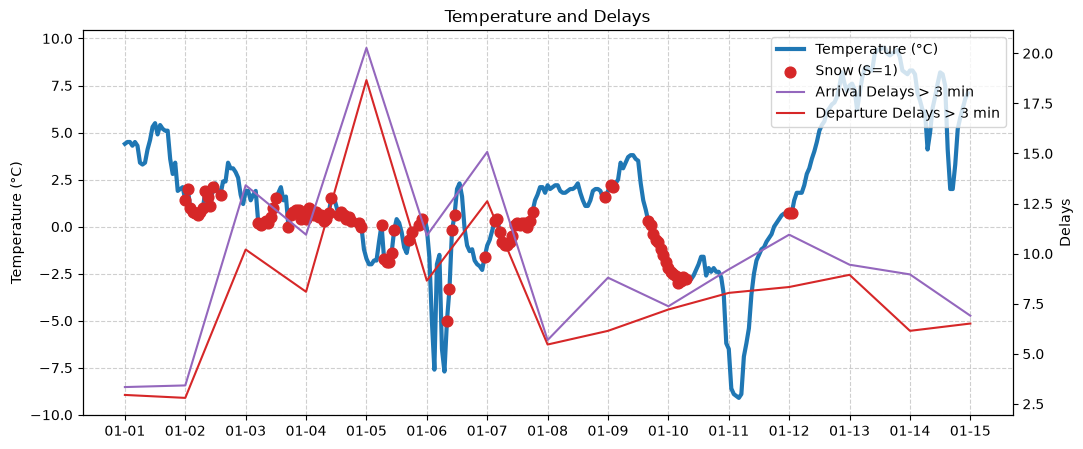

In [5]:
fig1, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()


line1 = ax1.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)
line2 = ax2.plot(daily_delay.index, daily_delay['arrival_delayed_3'],
        label='Arrival Delays > 3 min', color = 'tab:purple')
line3 = ax2.plot(daily_delay.index, daily_delay['departure_delayed_3'],
        label='Departure Delays > 3 min', color = 'tab:red')




snow_df = df_weather[df_weather['S'] == 1]
scatter1 = ax1.scatter(snow_df['datetime'], snow_df['T_C'], color='tab:red', s=60, zorder=5, label='Snow (S=1)')

ax1.set_ylabel('Temperature (°C)')
ax1.set_title(f'Temperature and Delays')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right')
  

ax2.set_ylabel('Delays')
ax2.tick_params(axis='y')

ax1.xaxis.set_major_locator(mdates.DayLocator(interval=1))

# 2. Format the labels to only show Month-Day (e.g., 01-01)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))


lines = line1 + [scatter1] + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')
plt.show()

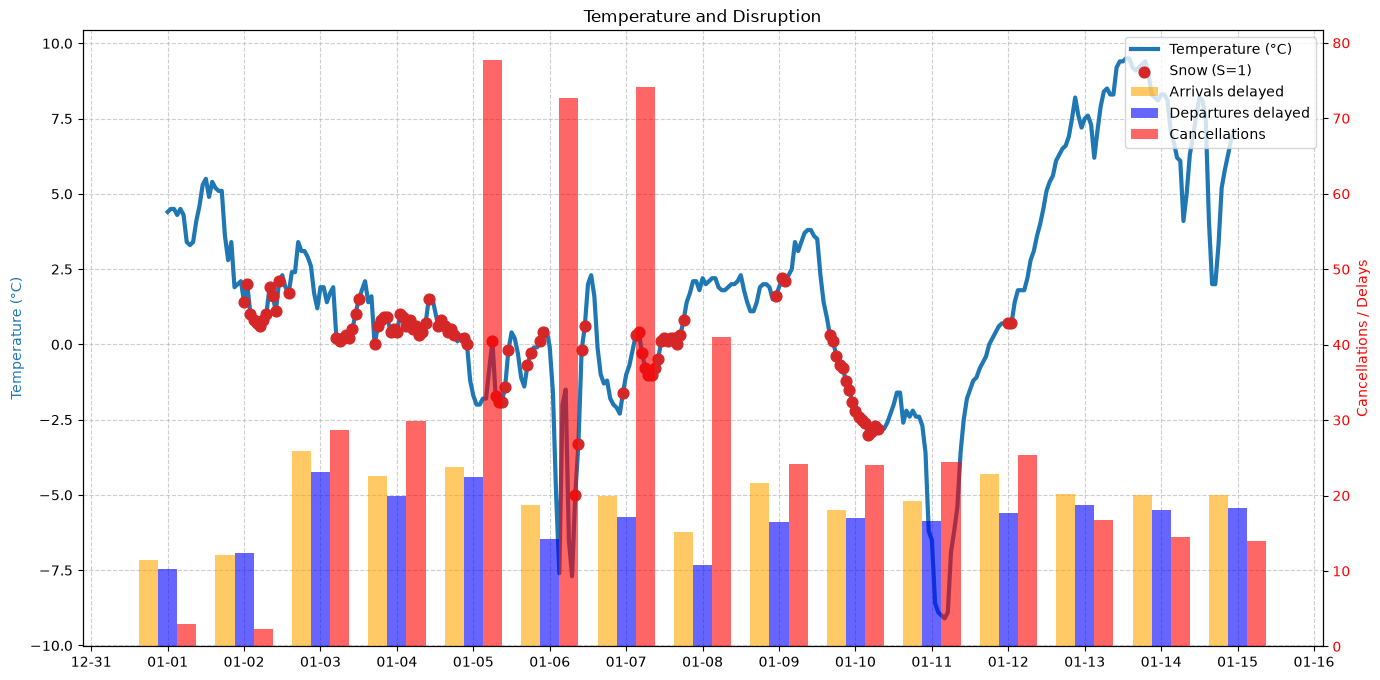

In [6]:

#visualisation 2
fig1, ax1 = plt.subplots(figsize=(16, 8))

# 1. Maak direct de tweede as aan
ax2 = ax1.twinx()
line1 = ax1.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)
snow_df = df_weather[df_weather['S'] == 1]
scatter1 = ax1.scatter(snow_df['datetime'], snow_df['T_C'], color='tab:red', s=60, zorder=5, label='Snow (S=1)')




bar_width = pd.Timedelta(hours= 6)


# 3. Plot de annuleringen op de TWEEDE as (ax2)
bar1 = ax2.bar(daily_delay.index - bar_width, daily_delay['arrival_delayed'], width = bar_width, label='Arrivals delayed', color='orange', alpha = 0.6)
bar2 = ax2.bar(daily_delay.index, daily_delay['departure_delayed'], width = bar_width, label='Departures delayed', color='blue', alpha = 0.6)
bar3 = ax2.bar(daily_delay.index + bar_width, daily_delay['cancelled'], width = bar_width, label='Cancellations', color='red', alpha = 0.6)



# 4. Opmaak voor as 1
ax1.set_ylabel('Temperature (°C)', color='tab:blue')
ax1.set_title('Temperature and Disruption')
ax1.grid(True, linestyle='--', alpha=0.6)

# 5. Opmaak voor as 2
ax2.set_ylabel('Cancellations / Delays', color='red')
ax2.tick_params(axis='y', labelcolor='red')

ax1.xaxis.set_major_locator(mdates.DayLocator(interval=1))

# 2. Format the labels to only show Month-Day (e.g., 01-01)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))

# 6. Gecombineerde legenda maken (zodat alles in één kader staat)
# We halen de lijnen/balken op en stoppen ze samen in ax1.legend
lines = line1 + [scatter1] + [bar1] + [bar2] + [bar3]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.show()


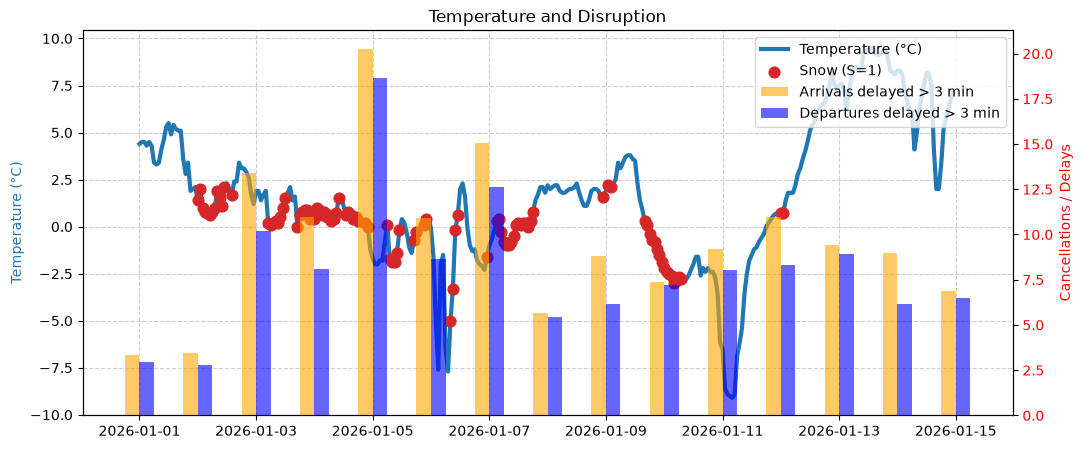

In [7]:

#visualisation 2
fig1, ax1 = plt.subplots(figsize=(12, 5))

# 1. Maak direct de tweede as aan
ax2 = ax1.twinx()
line1 = ax1.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)
snow_df = df_weather[df_weather['S'] == 1]
scatter1 = ax1.scatter(snow_df['datetime'], snow_df['T_C'], color='tab:red', s=60, zorder=5, label='Snow (S=1)')




bar_width = pd.Timedelta(hours= 6)


# 3. Plot de annuleringen op de TWEEDE as (ax2)
bar1 = ax2.bar(daily_delay.index - 0.5 * bar_width, daily_delay['arrival_delayed_3'], width = bar_width, label='Arrivals delayed > 3 min', color='orange', alpha = 0.6)
bar2 = ax2.bar(daily_delay.index + 0.5 * bar_width, daily_delay['departure_delayed_3'], width = bar_width, label='Departures delayed > 3 min', color='blue', alpha = 0.6)



# 4. Opmaak voor as 1
ax1.set_ylabel('Temperature (°C)', color='tab:blue')
ax1.set_title('Temperature and Disruption')
ax1.grid(True, linestyle='--', alpha=0.6)

# 5. Opmaak voor as 2
ax2.set_ylabel('Cancellations / Delays', color='red')
ax2.tick_params(axis='y', labelcolor='red')


# 6. Gecombineerde legenda maken (zodat alles in één kader staat)
# We halen de lijnen/balken op en stoppen ze samen in ax1.legend
lines = line1 + [scatter1] + [bar1] + [bar2]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.show()


Detailed look

            Date       Type   train_id scheduled_arrival  arr_delay  \
0     2026-03-01  Intercity  162058996             06:40        0.0   
1     2026-03-01  Intercity  162059577             06:39        1.0   
2     2026-03-01  Intercity  162058218             06:53        0.0   
3     2026-03-01   Sprinter  162059405             07:03        2.0   
4     2026-03-01  Intercity  162058307             07:07        0.0   
...          ...        ...        ...               ...        ...   
42689 2026-04-30  Intercity  165792010             22:27        0.0   
42690 2026-04-30   Sprinter  165792131             22:34        0.0   
42691 2026-04-30  Intercity  165791852             22:37        0.0   
42692 2026-04-30  Intercity  165792607             22:47        2.0   
42693 2026-04-30  Intercity  165790497             22:52        3.0   

      arr_cancelled scheduled_departure  dep_delay dep_cancelled  \
0             False               06:53        0.0         False   
1          

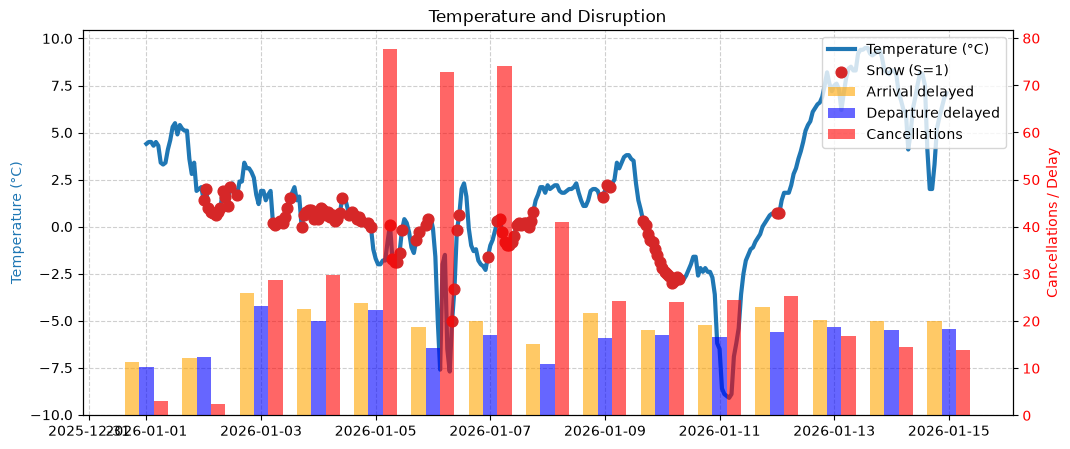

In [12]:

#visualisation 


df_train = load_train_data(start_period= '03-01-2026', end_period= '09-01-2026')

print(df_train)
fig1, ax1 = plt.subplots(figsize=(12, 5))

# 1. Maak direct de tweede as aan
ax2 = ax1.twinx()
ax1.plot(df_weather['datetime'], df_weather['T_C'], label='Temperature (°C)', color='tab:blue', linewidth=3.0)
snow_df = df_weather[df_weather['S'] == 1]
ax1.scatter(snow_df['datetime'], snow_df['T_C'], color='tab:red', s=60, zorder=5, label='Snow (S=1)')




bar_width = pd.Timedelta(hours= 6)


# 3. Plot de annuleringen op de TWEEDE as (ax2)
bar1 = ax2.bar(daily_delay.index - pd.Timedelta(hours = 6), daily_delay['arrival_delayed'], width = bar_width, label='Arrival delayed', color='orange', alpha = 0.6)
bar2 = ax2.bar(daily_delay.index, daily_delay['departure_delayed'], width = bar_width, label='Departure delayed', color='blue', alpha = 0.6)
bar3 = ax2.bar(daily_delay.index + pd.Timedelta(hours = 6), daily_delay['cancelled'], width = bar_width, label='Cancellations', color='red', alpha = 0.6)



# 4. Opmaak voor as 1
ax1.set_ylabel('Temperature (°C)', color='tab:blue')
ax1.set_title('Temperature and Disruption')
ax1.grid(True, linestyle='--', alpha=0.6)

# 5. Opmaak voor as 2
ax2.set_ylabel('Cancellations / Delay', color='red')
ax2.tick_params(axis='y', labelcolor='red')


# 6. Gecombineerde legenda maken (zodat alles in één kader staat)
# We halen de lijnen/balken op en stoppen ze samen in ax1.legend
lines = line1 + [scatter1] + [bar1] + [bar2] + [bar3]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.show()
